# Exercises XP Ninja: Airline Passenger Forecasting with RNNs

This is a guided notebook for the exercise on the platform. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points appear for important concepts.

> **IMPORTANT: delete last row in the downloaded dataset "International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60"**

## What you will learn
- Preprocess and analyze a time series
- Build and train Simple RNN, LSTM, GRU
- Evaluate and compare models
- Visualize training history and predictions

## What you will create
- A predictive model for the number of international airline passengers

## How I run this notebook
- Open the file in Google Colab (File → Upload notebook).
- Run all cells top to bottom (Runtime → Run all). The notebook downloads the airline zip from the course GitHub itself and cleans it, so no local files are needed.
- Seeds are fixed (`set_random_seed(42)` before the models are built), so the numbers should be close to mine.
- **CPU run (what I used here):** I ran the full settings, 100 epochs with early stopping. The series has only 144 months, so no reduction was needed.
- **Colab GPU:** the same settings apply. A GPU would make little difference on a series this small.

# Part 1: Data preparation

**As stated in the exercise**
Load the dataset, inspect it, drop rows with missing values, scale to a suitable range, and make supervised sequences using the past 6 months to predict the next month.

**My addition (not in the template): download and clean the data**
The template says to delete the footer by hand. This cell does it for you, so the PREFILLED loader below can stay as written.

In [1]:
# What this cell does: downloads the course zip, drops the blank line and the footer, and writes the cleaned CSV
import io, re, urllib.request, zipfile
from pathlib import Path

ZIP_URL = ("https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/"
           "Week%206/W6D4/Airline%20Passenger%20Forecasting%20by%20RNN,%20LSTM,%20%26%20GRU.zip")
OUT_PATH = Path('./data/international-airline-passengers.csv')  # same path as DATA_PATH below

with urllib.request.urlopen(ZIP_URL, timeout=120) as resp:
    zip_bytes = resp.read()

with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
    csv_name = next(n for n in zf.namelist() if n.lower().endswith('.csv'))
    text = zf.read(csv_name).decode('utf-8-sig')

lines = [ln.strip() for ln in text.splitlines()]
header, body = lines[0], lines[1:]

# A real data row is a date like "1949-01" (quotes optional), a comma, then a number
row_pattern = re.compile(r'^"?\d{4}-\d{2}"?,\s*\d+(\.\d+)?$')
data_rows = [ln for ln in body if row_pattern.match(ln)]
dropped = [ln for ln in body if ln and not row_pattern.match(ln)]
print('Dropped (blank line and footer):', dropped)

assert len(data_rows) == 144, f'expected 144 monthly rows, got {len(data_rows)}'
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
OUT_PATH.write_text('\n'.join([header] + data_rows) + '\n', encoding='utf-8')
print('Wrote', OUT_PATH, 'with', len(data_rows), 'rows')

Dropped (blank line and footer): ['International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60']
Wrote data/international-airline-passengers.csv with 144 rows


**PREFILLED just execute**
Imports, path, loader, and basic inspection helpers.

**What this cell does:** imports the libraries, sets the `DATA_PATH` to the cleaned CSV, loads it with the checks, and prints the shape and the first and last rows.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

pd.set_option('display.max_columns', 50)

# Change this to your CSV path if needed
DATA_PATH = Path('./data/international-airline-passengers.csv')  # To-Do: change if your file is elsewhere

def load_air_passengers(csv_path: Path):
    df = pd.read_csv(csv_path)
    # strip spaces in header
    df.columns = [str(c).strip() for c in df.columns]
    cols = list(df.columns)

    # try to detect by name
    date_col = next((c for c in cols if str(c).lower().startswith(("month","date"))), None)
    value_col = next((c for c in cols if str(c).lower().startswith(("pass","value"))), None)

    # fallback: assume 2-column file [date, value]
    if date_col is None or value_col is None:
        if len(cols) < 2:
            raise ValueError("Expected at least 2 columns [date, value].")
        date_col, value_col = cols[0], cols[1]

    # parse and clean
    df[date_col] = pd.to_datetime(df[date_col], errors="raise")
    df[value_col] = pd.to_numeric(df[value_col], errors="coerce")
    df = df.dropna(subset=[value_col])
    df = df.rename(columns={date_col: "Date", value_col: "Passengers"})
    df = df.sort_values("Date").reset_index(drop=True)
    return df[["Date","Passengers"]]


df = load_air_passengers(DATA_PATH)
print('Shape:', df.shape)
display(df.head())
display(df.tail())
display(df.describe())

Shape: (144, 2)


,Date,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


,Date,Passengers
139,1960-08-01,606
140,1960-09-01,508
141,1960-10-01,461
142,1960-11-01,390
143,1960-12-01,432


,Date,Passengers
count,144,144.000000
mean,1954-12-16 05:00:00,280.298611
min,1949-01-01 00:00:00,104.000000
25%,1951-12-24 06:00:00,180.000000
50%,1954-12-16 12:00:00,265.500000
75%,1957-12-08 18:00:00,360.500000
max,1960-12-01 00:00:00,622.000000
std,NaN,119.966317


**To-Do (code):** Drop rows with missing values then recheck that no NaNs remain.

**What this cell does:** drops any rows with NaN and asserts that none are left.

In [3]:
# To-Do (filled in): handle missing values
# Drop any rows with NaN, then check that none are left
df = df.dropna().reset_index(drop=True)
assert df.isna().sum().sum() == 0, 'There are still missing values'
print('Remaining NaNs:', int(df.isna().sum().sum()), '| rows:', len(df))

Remaining NaNs: 0 | rows: 144


**Learning point**
Scale before windowing for stable gradients. For univariate series a MinMax scaler to [0,1] is often sufficient. Keep the scaler to invert predictions later.

**PREFILLED just execute**
Scaling and sequence maker using past 6 months to predict month t+1. Chronological split into train and test.

**What this cell does:** builds the 6-month input windows and the next-month targets. It scales the series to [0, 1], splits it 80/20 by time, and makes the train and test sequences.

In [4]:
def make_sequences(values_1d: np.ndarray, lookback: int = 6, horizon: int = 1):
    X, y = [], []
    for i in range(len(values_1d) - lookback - horizon + 1):
        X.append(values_1d[i:i+lookback])
        y.append(values_1d[i+lookback:i+lookback+horizon])
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    # reshape to [samples, timesteps, features=1]
    return X.reshape(len(X), lookback, 1), y.reshape(len(y), horizon)

LOOKBACK = 6
HORIZON = 1

# Scale
scaler = MinMaxScaler(feature_range=(0,1))
series = df[['Passengers']].astype('float32')
series_scaled = scaler.fit_transform(series)

# Split by time 80-20
split_idx = int(len(series_scaled) * 0.8)
train_vals = series_scaled[:split_idx].ravel()
test_vals  = series_scaled[split_idx - LOOKBACK:].ravel()  # overlap LOOKBACK for continuity

X_train, y_train = make_sequences(train_vals, lookback=LOOKBACK, horizon=HORIZON)
X_test,  y_test  = make_sequences(test_vals,  lookback=LOOKBACK, horizon=HORIZON)
print({'X_train': X_train.shape, 'y_train': y_train.shape, 'X_test': X_test.shape, 'y_test': y_test.shape})

{'X_train': (109, 6, 1), 'y_train': (109, 1), 'X_test': (29, 6, 1), 'y_test': (29, 1)}


**To-Do (written):** Explain why we overlapped LOOKBACK points into the test split window.

**My answer:**
I overlap the split by LOOKBACK (6) points so that the first test target has a full 6-month window. The test split starts at `split_idx - 6`, so the first test target (index 115, the first point after the split) has its six inputs (indices 109 to 114) directly in front of it. Without the overlap, the first six test months would have less than six months of history, and I would only get 23 test windows instead of 29.

This does not leak future test values into training. The overlapped months are older than the test targets they feed, so they are only past inputs. The training targets still stop at index 114 (`split_idx - 1`), so no test value is ever used as a training target. The split stays in time order and nothing is shuffled.

![](./figs/1.gif)

# Part 2: Model building

**As stated in the exercise**
Build Simple RNN, LSTM, and GRU. Use Adam and MSE. Print summaries.

**PREFILLED just execute**
Keras imports and a helper to build each model.

**What this cell does:** defines the three model builders. Each one has two recurrent layers and a Dense output for the next month.

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models

# To-Do (filled in): two stacked recurrent layers. The first returns its full sequence
# so the second layer can read it; the second returns only its last state for the Dense head.
def build_simple_rnn(units=32, lookback=LOOKBACK, features=1):
    model = models.Sequential([
        layers.Input(shape=(lookback, features)),
        layers.SimpleRNN(units, return_sequences=True),
        layers.SimpleRNN(units, return_sequences=False),
        layers.Dense(HORIZON)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def build_lstm(units=32, lookback=LOOKBACK, features=1):
    model = models.Sequential([
        layers.Input(shape=(lookback, features)),
        layers.LSTM(units, return_sequences=True),
        layers.LSTM(units, return_sequences=False),
        layers.Dense(HORIZON)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def build_gru(units=32, lookback=LOOKBACK, features=1):
    model = models.Sequential([
        layers.Input(shape=(lookback, features)),
        layers.GRU(units, return_sequences=True),
        layers.GRU(units, return_sequences=False),
        layers.Dense(HORIZON)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

print(tf.__version__)

2.21.0


**To-Do (code):** Fill the model bodies above, then instantiate `model_rnn`, `model_lstm`, and `model_gru`. Call `summary()` for each.

**What this cell does:** builds the three models and prints their summaries.

In [6]:
# To-Do (filled in): build and summarize models
tf.keras.utils.set_random_seed(42)  # fixed seed so the weights start the same way on every run
model_rnn  = build_simple_rnn(units=32)
model_lstm = build_lstm(units=32)
model_gru  = build_gru(units=32)
model_rnn.summary(); model_lstm.summary(); model_gru.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 6, 32)          │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_1"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 6, 32)          │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,729 (38.00 KB)

 Trainable params: 9,729 (38.00 KB)

 Non-trainable params: 0 (0.00 B)

# Part 3: Model training

**As stated in the exercise**
Train the three models. Use early stopping.

**PREFILLED just execute**
Callbacks and a helper to fit a model and return history.

**What this cell does:** defines `fit_model`, which runs `fit` with early stopping and learning-rate reduction, and `plot_history`, which draws the loss curves.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def fit_model(model, X_tr, y_tr, X_te, y_te, epochs=100, batch=16):
    es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    rl = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
    h = model.fit(
        X_tr, y_tr,
        validation_data=(X_te, y_te),
        epochs=epochs,
        batch_size=batch,
        callbacks=[es, rl],
        verbose=2
    )
    return h

def plot_history(history, title='Training history'):
    plt.figure(figsize=(6,4))
    plt.plot(history.history['loss'], label='loss')
    if 'val_loss' in history.history:
        plt.plot(history.history['val_loss'], label='val_loss')
    plt.title(title)
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.tight_layout(); plt.show()

**To-Do (code):** Train each model for up to 100 epochs with early stopping. Plot histories using `plot_history`.

**What this cell does:** trains each model for up to 100 epochs, stops early if validation loss stops improving, and plots the loss curves.

Epoch 1/100


7/7 - 1s - 202ms/step - loss: 0.0324 - val_loss: 0.0285 - learning_rate: 0.0010


Epoch 2/100


7/7 - 0s - 9ms/step - loss: 0.0145 - val_loss: 0.0643 - learning_rate: 0.0010


Epoch 3/100


7/7 - 0s - 8ms/step - loss: 0.0095 - val_loss: 0.0150 - learning_rate: 0.0010


... (393 outputs left out)

7/7 - 0s - 11ms/step - loss: 0.0023 - val_loss: 0.0075 - learning_rate: 1.2500e-04


Epoch 96/100


7/7 - 0s - 10ms/step - loss: 0.0023 - val_loss: 0.0076 - learning_rate: 1.2500e-04


{'epochs_run': {'rnn': 91, 'lstm': 14, 'gru': 96}}


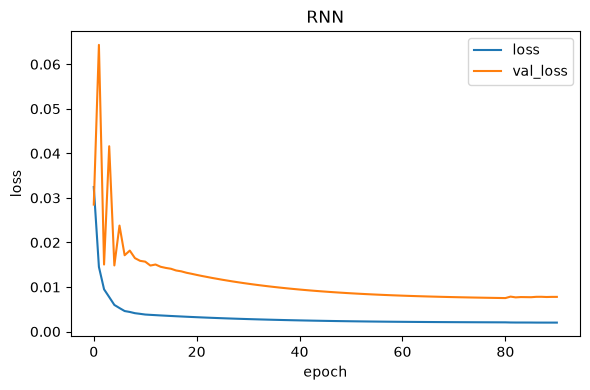

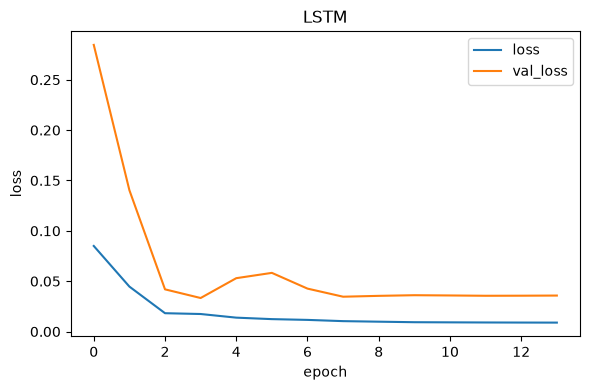

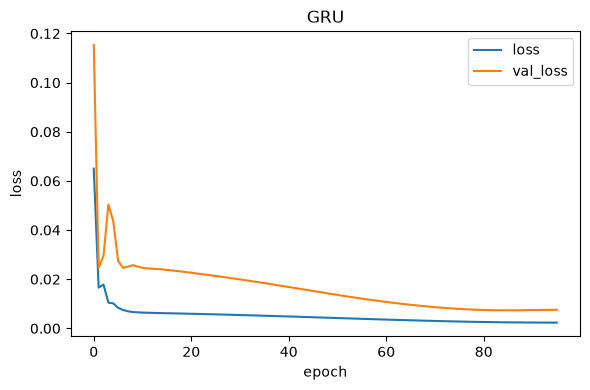

In [8]:
# To-Do (filled in): train and plot
h_rnn  = fit_model(model_rnn,  X_train, y_train, X_test, y_test, epochs=100, batch=16)
h_lstm = fit_model(model_lstm, X_train, y_train, X_test, y_test, epochs=100, batch=16)
h_gru  = fit_model(model_gru,  X_train, y_train, X_test, y_test, epochs=100, batch=16)
print({'epochs_run': {'rnn': len(h_rnn.history['loss']), 'lstm': len(h_lstm.history['loss']), 'gru': len(h_gru.history['loss'])}})
plot_history(h_rnn,  title='RNN')
plot_history(h_lstm, title='LSTM')
plot_history(h_gru,  title='GRU')

# Part 4: Visualizing training history

**As stated in the exercise**
Plot training and validation loss for each model and compare.

**To-Do (written):** Compare the learning curves. Which model converges faster and to a lower validation loss. Explain briefly.

**My answer:**
I read the curves on validation loss, since early stopping watches that value.
- **Faster:** the simple RNN drops the fastest. Its validation loss goes below 0.01 at epoch 37. The GRU gets there at epoch 65, and the LSTM never gets there in its 14 epochs.
- **Lower:** the GRU ends with the lowest best validation loss (0.0073 at epoch 86, against 0.0075 for the RNN at epoch 81). The gap is very small.
- **LSTM:** its validation loss starts high (0.28 after epoch 1) and reaches its best value of 0.033 at epoch 4. After that it does not improve, so early stopping (patience 10) ends training at epoch 14. Its training loss keeps falling, so this is not a simple overfit. I did not find the exact cause.

# Part 5: Making predictions

**As stated in the exercise**
Predict on test data, then invert scaling to the original units.

**PREFILLED just execute**
Helper to invert scaling and a function to get predictions from a model.

**What this cell does:** defines helpers that undo the scaling for the predictions and the targets.

In [9]:
def invert_scale(scaled_values):
    # scaled_values shape [N, 1]
    return scaler.inverse_transform(scaled_values)

def predict_and_invert(model, X):
    preds_scaled = model.predict(X, verbose=0)
    # ensure shape [N, 1]
    preds_scaled = np.asarray(preds_scaled).reshape(-1, 1)
    return invert_scale(preds_scaled)

def true_targets_in_original(y_seq):
    # y_seq shape [N, HORIZON]
    return invert_scale(y_seq.reshape(-1, 1))

**To-Do (code):** Generate predictions for each model and invert scaling for both predictions and targets.

**What this cell does:** predicts on the test windows and converts both predictions and targets back to passenger counts.

In [10]:
# To-Do (filled in): predictions and inverse scaling
y_true = true_targets_in_original(y_test)
yhat_rnn  = predict_and_invert(model_rnn,  X_test)
yhat_lstm = predict_and_invert(model_lstm, X_test)
yhat_gru  = predict_and_invert(model_gru,  X_test)

# Part 6: Visualizing prediction results

**As stated in the exercise**
Plot actual vs predicted for each model and compare accuracy.

**PREFILLED just execute**
Plot helpers for predictions.

**What this cell does:** defines `plot_preds` (actual vs predicted) and `rmse`.

In [11]:
def plot_preds(y_true, yhat, title):
    plt.figure(figsize=(7,3))
    plt.plot(y_true.ravel(), label='actual')
    plt.plot(yhat.ravel(),  label='predicted')
    plt.title(title)
    plt.xlabel('time index')
    plt.ylabel('passengers')
    plt.legend(); plt.tight_layout(); plt.show()

def rmse(a, b):
    a = a.ravel(); b = b.ravel()
    return float(np.sqrt(np.mean((a - b)**2)))

**To-Do (code):** Plot predictions for each model. Compute RMSE for RNN, LSTM, and GRU. Compare which is best on this series.

**What this cell does:** plots actual vs predicted for each model and prints the test RMSE (in thousands of passengers).

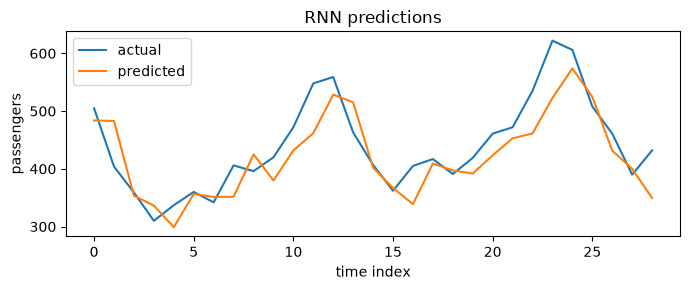

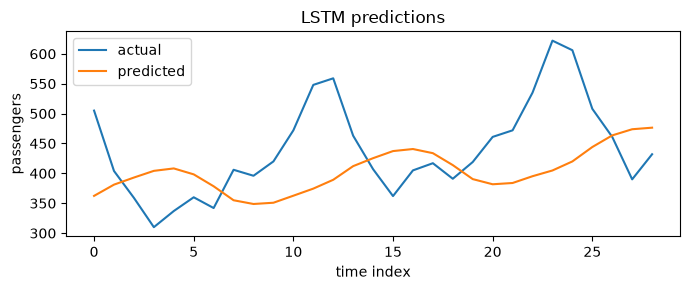

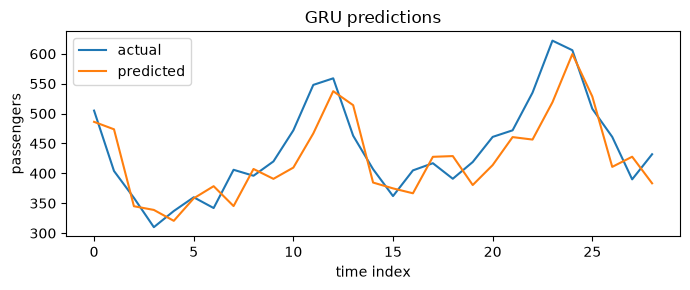

{'rmse_rnn': 44.9, 'rmse_lstm': 94.54, 'rmse_gru': 44.39}


In [12]:
# To-Do (filled in): plots and metrics
plot_preds(y_true, yhat_rnn,  'RNN predictions')
plot_preds(y_true, yhat_lstm, 'LSTM predictions')
plot_preds(y_true, yhat_gru,  'GRU predictions')
print({'rmse_rnn': round(rmse(y_true, yhat_rnn), 2),
       'rmse_lstm': round(rmse(y_true, yhat_lstm), 2),
       'rmse_gru': round(rmse(y_true, yhat_gru), 2)})

**My answer:**
**My pick is the GRU, by a small margin.** Test RMSE (in thousands of passengers): GRU 44.39, RNN 44.90, LSTM 94.54.
- The LSTM is clearly worst. Its predictions stay between about 350 and 480, so it misses the seasonal peaks (the actual test values reach 622).
- The RNN and GRU follow the seasonal wave. Both miss the largest peak (actual 622, RNN 523, GRU 519). The GRU is closer on the next peak (actual 606, RNN 574, GRU 600).
- I also re-ran the three models with seeds 1, 2 and 3 (a scratch check, not in the notebook). The GRU had the lowest RMSE on all four seeds, the RNN was second on all four, and the LSTM was last on all four. The RNN vs GRU gap is about 1 RMSE on 29 test points, so I would call the GRU best here, but not a clear win.

**Caveats:**
1. The test windows are also the validation set for early stopping, learning-rate reduction and `restore_best_weights`, so these RMSE numbers are optimistic. A clean version would hold out part of the training months as validation.
2. The prefilled scaler is fitted on all 144 months, including the test months. Fitting it on the training months only would avoid that small leak.
3. The LSTM stopped at epoch 13 or 14 on all four seeds, on an early plateau. That points to this training setup (learning rate, patience, batch size) and not only to the LSTM's ability. I did not tune it, so I cannot say how good an LSTM could be here.

**Learning point**
Do not shuffle a univariate time series split. Keep the chronological order. Use early stopping on validation loss to avoid overfitting and reduce training time. For multi-step forecasts, increase the horizon and adapt the output layer size.